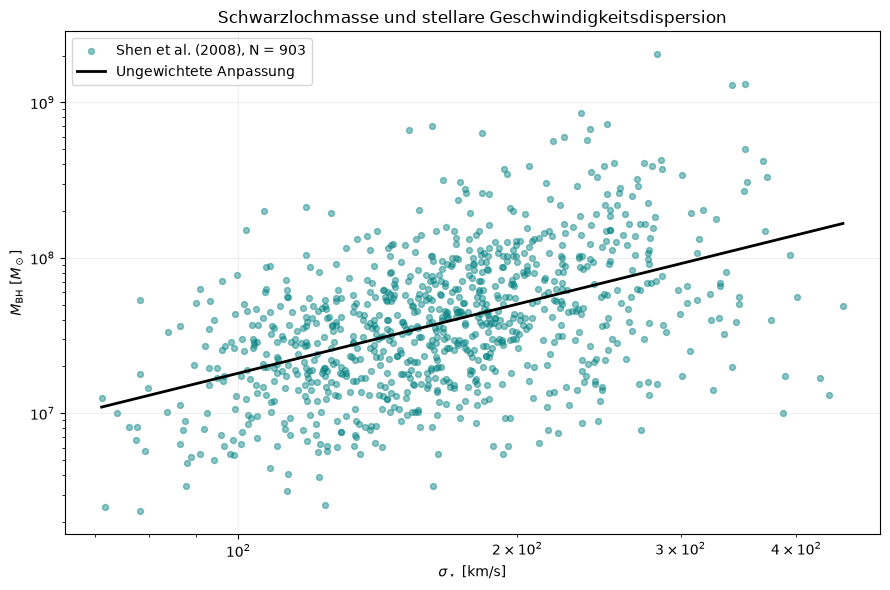

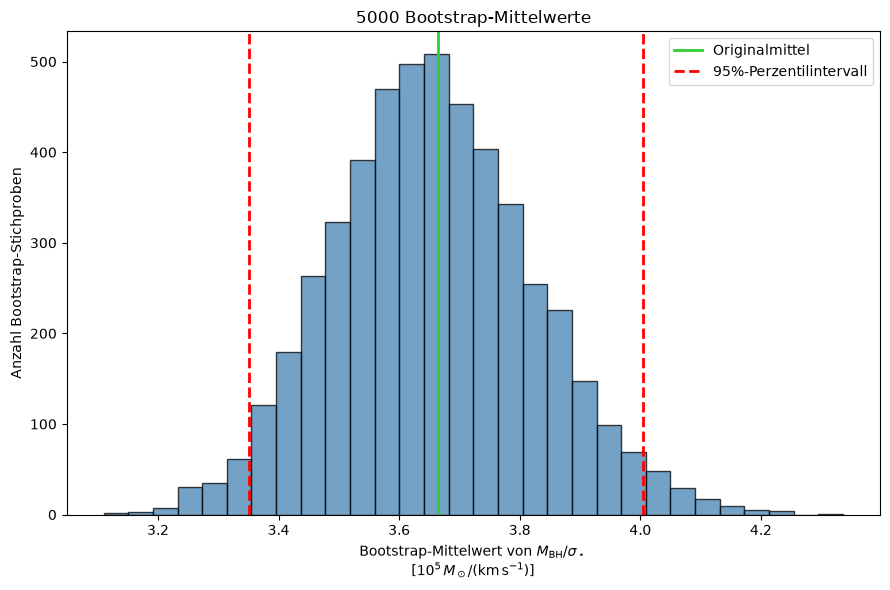

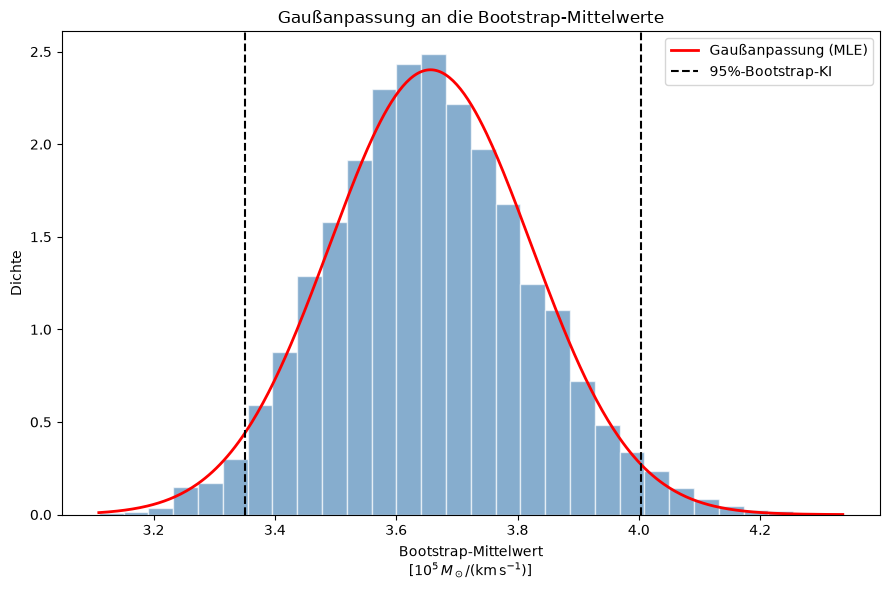

In [1]:


import numpy as np
import matplotlib.pyplot as plt
from astroquery.vizier import Vizier
from scipy.stats import norm

vizier = Vizier(
    columns=["Csigma", "logM"],
    row_limit=-1,
    vizier_server="vizier.cfa.harvard.edu"
)
vizier.TIMEOUT = 120

tabellen = vizier.get_catalogs("J/AJ/135/928/table1")

if len(tabellen) == 0:
    raise RuntimeError("Keine Daten erhalten.")

tabelle = tabellen[0]

sigma = np.ma.asarray(tabelle["Csigma"], dtype=float).filled(np.nan)
logM = np.ma.asarray(tabelle["logM"], dtype=float).filled(np.nan)

gueltig = np.isfinite(sigma) & np.isfinite(logM) & (sigma > 0)
sigma = sigma[gueltig]
logM = logM[gueltig]
masse = 10.0**logM

N = len(masse)
if N < 3 or np.ptp(sigma) == 0:
    raise ValueError("Zu wenige geeignete Daten für die Auswertung.")


x = np.log10(sigma / 200.0)
b, a = np.polyfit(x, logM, 1)

sigma_linie = np.geomspace(sigma.min(), sigma.max(), 300)
masse_linie = 10.0**(
    a + b * np.log10(sigma_linie / 200.0)
)

fig, ax = plt.subplots(figsize=(9, 6))

ax.scatter(
    sigma, masse,
    s=18, alpha=0.45, color="teal",
    label=f"Shen et al. (2008), N = {N}"
)
ax.plot(
    sigma_linie, masse_linie,
    color="black", linewidth=2,
    label="Ungewichtete Anpassung"
)

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel(r"$\sigma_\star$ [km/s]")
ax.set_ylabel(r"$M_{\mathrm{BH}}$ [$M_\odot$]")
ax.set_title("Schwarzlochmasse und stellare Geschwindigkeitsdispersion")
ax.grid(alpha=0.2)
ax.legend()

fig.tight_layout()
fig.savefig("01_Masse_Sigma.png", dpi=300, bbox_inches="tight")
plt.show()


c = masse / sigma
mittel_original = np.mean(c)

rng = np.random.default_rng(42069)
bootstrap_mittel = np.empty(5000)

for i in range(len(bootstrap_mittel)):
    stichprobe = rng.choice(c, size=N, replace=True)
    bootstrap_mittel[i] = np.mean(stichprobe)

unten, oben = np.percentile(bootstrap_mittel, [2.5, 97.5])

# Achsenwerte in Einheiten von 10^5 Msun/(km/s)
skala = 1e5
bootstrap_skaliert = bootstrap_mittel / skala


fig, ax = plt.subplots(figsize=(9, 6))

ax.hist(
    bootstrap_skaliert,
    bins=30,
    color="steelblue",
    edgecolor="black",
    alpha=0.75
)
ax.axvline(
    mittel_original / skala,
    color="limegreen", linewidth=2,
    label="Originalmittel"
)
ax.axvline(
    unten / skala,
    color="red", linestyle="--", linewidth=2,
    label="95%-Perzentilintervall"
)
ax.axvline(
    oben / skala,
    color="red", linestyle="--", linewidth=2
)

ax.set_xlabel(
    r"Bootstrap-Mittelwert von $M_{\mathrm{BH}}/\sigma_\star$"
    "\n"
    r"[$10^5\,M_\odot/(\mathrm{km\,s^{-1}})$]"
)
ax.set_ylabel("Anzahl Bootstrap-Stichproben")
ax.set_title("5000 Bootstrap-Mittelwerte")
ax.legend()

fig.tight_layout()
fig.savefig("02_Bootstrap.png", dpi=300, bbox_inches="tight")
plt.show()


mu_mle, sigma_mle = norm.fit(bootstrap_skaliert)

if sigma_mle <= 0:
    raise ValueError("Keine Streuung für die Gaußanpassung vorhanden.")

xx = np.linspace(
    bootstrap_skaliert.min(),
    bootstrap_skaliert.max(),
    400
)

fig, ax = plt.subplots(figsize=(9, 6))

ax.hist(
    bootstrap_skaliert,
    bins=30,
    density=True,
    color="steelblue",
    edgecolor="white",
    alpha=0.65
)
ax.plot(
    xx,
    norm.pdf(xx, loc=mu_mle, scale=sigma_mle),
    color="red", linewidth=2,
    label="Gaußanpassung (MLE)"
)
ax.axvline(
    unten / skala,
    color="black", linestyle="--",
    label="95%-Bootstrap-KI"
)
ax.axvline(
    oben / skala,
    color="black", linestyle="--"
)

ax.set_xlabel(
    r"Bootstrap-Mittelwert"
    "\n"
    r"[$10^5\,M_\odot/(\mathrm{km\,s^{-1}})$]"
)
ax.set_ylabel("Dichte")
ax.set_title("Gaußanpassung an die Bootstrap-Mittelwerte")
ax.legend()

fig.tight_layout()
fig.savefig("03_Gauss_MLE.png", dpi=300, bbox_inches="tight")
plt.show()